# Day 1 · dx_9487, and why a bag of codes fails

**The problem.** IRIX Dx code `dx_9487` (Atypical Chest Pain) currently routes every case
to manual review at RUW. It maps to five nonspecific ICD-10 codes:

| Code | Meaning | Share of dx_9487 |
|---|---|---|
| R07.89 | Other chest pain | 48.1% |
| R07.9  | Chest pain, unspecified | 42.5% |
| R07.2  | Precordial pain | 6.5% |
| R07.8  | Other chest pain | 1.8% |
| R07.82 | Intercostal pain | 1.1% |

Every one of these is ambiguous by construction — "chest pain" can mean a real cardiac
issue or a benign cause (musculoskeletal, GI, anxiety/panic). The code alone doesn't say
which, so every case currently gets manual review, which is costly and slow.

**Today's goal:** get the OMOP extract for this cohort loaded as one event stream,
understand the four preprocessing decisions baked into it, and see the exact failure that
motivates the rest of the week.

**The working hypothesis** (to test, not assume): a meaningful share of dx_9487 cases are
anxiety/panic presentations coded as chest pain. If true, comorbid anxiety/panic Dx and
SSRI/benzodiazepine Rx codes should associate strongly with dx_9487. The analysis has to be
built so the data can show something else instead — GERD, costochondritis, or genuine
cardiac workup — not just confirm the story going in.

### Summary

Every unsupervised method is a distance function plus a search procedure. Changing the
representation moves the answer more than changing the algorithm does, so the leverage is
upstream. Today is the upstream.

### Three things that all get called "pattern"

| Term | What it is | Built on | Auditable? |
|---|---|---|---|
| **Cluster** | a group of similar patients | Day 2 | partly |
| **Motif** | a recurring *ordered* subsequence | Day 3 | yes |
| **Embedding** | a direction in a learned space | Day 4 | no |

Deciding which of these is the actual deliverable for the dx_9487 triage decision is the
single most important scoping question on this project.

### Technique chosen per subtopic

| Subtopic | We use | Mentioned only |
|---|---|---|
| Similarity | **cosine** on binary codes | Jaccard, Dice, Gower, Mahalanobis |
| Linear reduction | **truncated SVD** | PCA (same thing, dense), ICA, factor analysis |
| Parts-based | **NMF** | archetypal analysis, sparse PCA |
| Non-linear view | **t-SNE** (ships with sklearn) | UMAP — better, `pip install umap-learn` |

## 0 · Getting the data

`ethos_omop.extract_cohort()` pulls the dx_9487 cohort: any patient carrying one of the
five R07.x codes, defined in `sql/chest_pain_cohort.sql`. It dumps the same shape
`extract_omop()` does — `master_*` as the source of truth, `ethos_dip` excluded on both
`concept_id` and `source_concept_id` for every domain table, standard-named symlinks for
`meds_etl_omop`, plus:

* **`concept.csv` slimmed** to the concept_ids the cohort actually references, instead of
  the full multi-million-row table.
* **`concept_ancestor` dumped too**, restricted to rows touching the cohort — needed for
  ontology rollup (unspecified chest-pain codes to their parents, drugs to ingredients).

```python
import ethos_omop as eo
eo.extract_cohort("../sql/chest_pain_cohort.sql")   # -> ../data_input/
```

The next cell runs this once (150,368 patients, all real Ethos production data) and skips
it on every re-run once `../data_input/` exists.

Without Snowflake, or when you want data whose answer you already know:

```bash
python make_demo_extract.py 2000
```

The demo extract has the **same schema** — integer `concept_id`s resolved through
`concept.csv`, `master_*` table names, the symlinks — plus a `truth.csv` giving each
patient's planted trajectory archetype. Real extracts have no `truth.csv`. That absence is
the whole problem this course is about, and every notebook here works either way.

*In plain terms: this is a one-time data export, like running a big report and saving the results as spreadsheets (CSV files) in a folder. Every cell below reads from that folder, not from Snowflake directly.*

In [1]:
import os
import ethos_omop as eo

OUT_DIR     = "../../inputs/chest_pain_cohort/"                     # extract_cohort() output, relative to repr_learn/
COHORT_SQL  = "../../sql/chest_pain_cohort.sql"   # relative to this notebook's cwd

# Runs once: if OUT_DIR is already populated, notebooks load from disk and never
# re-hit Snowflake. Delete OUT_DIR (or pick a different one) to force a re-pull.
if not os.path.isdir(OUT_DIR):
    eo.extract_cohort(COHORT_SQL, out_dir=OUT_DIR)
else:
    print(f"{OUT_DIR}/ already populated -- skipping extract_cohort(). "
          f"Delete it to re-pull from Snowflake.")

../../inputs/chest_pain_cohort// already populated -- skipping extract_cohort(). Delete it to re-pull from Snowflake.


### v2 · Visit pruning (care-driven bias)

The bundles from v1 reflect **care delivery, not condition**: pharmacy, office and ED visits are the
most common tokens and pull unrelated patients together. v2 changes one thing, at the load step
below: every event whose `domain` or `vocabulary_id` is "visit" is dropped before tagging.
Everything after it is unchanged, so v1 and v2 results are directly comparable.

Side effects to expect: the `ed_visit` codeset tag disappears (it sits on visit concepts), the
Table 1 `ed_visit` row reads 0%, and the proxy lookback window can shrink for patients whose first or
last record was a visit. The NMF fit is saved as `nmf_k{k}_chestpain_v2.npz`, so v1's file is not overwritten.


In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 150); pd.set_option('display.max_columns', 40)

DOMAINS = ['Visit', 'Condition', 'Drug', 'Procedure', 'Measurement']   # Visit stays in the load so we can show before vs after

concept  = eo.load_concept(OUT_DIR)
codesets = eo.build_codesets(concept, verbose=True)
raw      = eo.load_events(OUT_DIR, domains=DOMAINS)
person   = eo.load_person(OUT_DIR)
truth    = eo.load_truth(OUT_DIR)                   # None against real data

# v2: drop every visit event BEFORE tagging (care-driven bias). A visit row is any row whose
# domain OR vocabulary is "visit"; pharmacy / office / ED visits otherwise dominate the bundles.
is_visit = (raw['domain'].astype(str).str.lower().eq('visit')
            | raw['vocabulary_id'].astype(str).str.lower().eq('visit'))
visits   = raw[is_visit]
events   = eo.tag_events(raw[~is_visit].reset_index(drop=True), codesets)

# ---- before / after pruning
tbl = (pd.DataFrame({'before': raw['domain'].value_counts(), 'after': events['domain'].value_counts()})
         .fillna(0).astype(int))
tbl.loc['TOTAL'] = [len(raw), len(events)]
tbl['removed_%'] = ((1 - tbl['after'] / tbl['before']) * 100).round(1)
print("events per domain, BEFORE vs AFTER visit pruning")
print(tbl.to_string())
print(f"\npatients:               {raw.person_id.nunique():>10,} -> {events.person_id.nunique():,}")
print(f"distinct concepts:      {raw.concept_id.nunique():>10,} -> {events.concept_id.nunique():,}")
print(f"median events/patient:  {raw.groupby('person_id').size().median():>10,.0f} -> "
      f"{events.groupby('person_id').size().median():,.0f}")
print("\nremoved rows by vocabulary:")
print(visits['vocabulary_id'].value_counts().head(10).to_string())
print("\ntop removed visit concepts:")
print(visits['concept_name'].value_counts().head(10).to_string())

visit_ids = set(visits['concept_id'])
lost      = sorted(t for t, ids in codesets.items() if set(ids) & visit_ids)
print("\ncurated codeset tags that sit on visit concepts (their events are gone):", lost or "none")
vanished  = set(raw['person_id']) - set(events['person_id'])
if vanished:
    print(f"WARNING: {len(vanished):,} patients had only visit events and are no longer in `events`")
del raw, visits                                      # free memory; `events` is the pruned stream from here on

print(f"\nevents {events.shape}   patients {events.person_id.nunique()}")
print(f"codeset coverage: {events.in_codeset.mean():.1%} of events carry a clinical tag")
print(f"truth labels: {'present (DEMO extract)' if truth is not None else 'ABSENT (real data)'}")
events.head(6)


beta_blocker        65 concepts   e.g. ['24 HR carvedilol phosphate 10 MG Extended Release Oral Capsule', '24 HR carvedilol phosphate 10 MG Extended Release Oral Capsule [Coreg]']
statin              43 concepts   e.g. ['amlodipine 10 MG / atorvastatin 10 MG Oral Tablet', 'amlodipine 10 MG / atorvastatin 20 MG Oral Tablet']
ssri                56 concepts   e.g. ['24 HR paroxetine hydrochloride 12.5 MG Extended Release Oral Tablet', '24 HR paroxetine hydrochloride 25 MG Extended Release Oral Tablet']
chest_pain           4 concepts   e.g. ['Chest pain', 'Chest pain on breathing']
anxiety             12 concepts   e.g. ['Adjustment disorder with mixed anxiety and depressed mood', 'Anxiety']
panic_attack         3 concepts   e.g. ['Agoraphobia without history of panic disorder', 'Panic disorder']
benzodiazepine      63 concepts   e.g. ['1 ML lorazepam 2 MG/ML Injection', '2 ML diazepam 5 MG/ML Auto-Injector']
gerd                 5 concepts   e.g. ['Gastro-esophageal reflux disease with 

,person_id,concept_id,event_date,domain,vocabulary_id,concept_code,concept_name,concept_class_id,token,tag,in_codeset
0,22,2212095,2019-04-25,Measurement,CPT4,80061,Lipid panel This panel must include the follow...,CPT4,CPT4/80061,lipid_panel_this_pan__cpt4__2212095,False
1,22,2212320,2019-04-25,Measurement,CPT4,82670,Estradiol; total,CPT4,CPT4/82670,estradiol_total__cpt4__2212320,False
2,22,2212816,2019-04-25,Measurement,CPT4,86376,"Microsomal antibodies (eg, thyroid or liver-ki...",CPT4,CPT4/86376,microsomal_antibodie__cpt4__2212816,False
3,22,4017355,2019-04-25,Measurement,SNOMED,104994008,"Triiodothyronine, free measurement",Procedure,SNOMED/104994008,triiodothyronine_fre__procedure__4017355,False
4,22,4068735,2019-04-25,Measurement,SNOMED,20436004,"Testosterone measurement, unbound",Procedure,SNOMED/20436004,testosterone_measure__procedure__4068735,False
5,22,4196731,2019-04-25,Measurement,SNOMED,313408009,Total thyroxine measurement,Procedure,SNOMED/313408009,total_thyroxine_meas__procedure__4196731,False


In [3]:
print(eo.describe_extract(OUT_DIR).to_string(index=False))

                           file     rows     MB
master_condition_occurrence.csv 19065882 2786.8
    master_visit_occurrence.csv 17911768 2235.5
master_procedure_occurrence.csv 11560700 1711.5
         master_observation.csv  9803534 1208.7
         master_measurement.csv  8441761 1143.8
       master_drug_exposure.csv  7614270 1466.5
           concept_ancestor.csv  1109876   24.1
                     person.csv   139416   18.2
                    concept.csv    29658    3.8
                      death.csv       18    0.0


## 1 · Four decisions 

Read these before trusting anything downstream. Each is a modelling choice, not a detail.

**1. Standard concepts only.** `load_events()` keeps `standard_concept == 'S'` and drops
`concept_id = 0` (unmapped). Note the exclusion idiom in the extract is
`IS DISTINCT FROM 'ethos_dip'`, not `<> 'ethos_dip'` — the latter silently drops NULLs.

*In plain terms: medical coding systems (ICD, SNOMED, etc.) have multiple ways to say the same thing. "Standard concepts" is OMOP's canonical, de-duplicated version of each code — we only keep those, so the same diagnosis isn't double-counted under two different code spellings.*

**2. `concept_code` stays a string.** Never let pandas parse it as numeric; leading zeros
and alphanumeric codes both break.

*In plain terms: some medical codes look like numbers (e.g. `"0042"`) but aren't meant to be treated as one — turning them into an actual number silently drops the leading zero and corrupts the code.*

**3. Claims carry a DATE, not a timestamp.** Same-day events have no true order.
`DOMAIN_ORDER` breaks ties deterministically — visit, then condition, procedure,
measurement, drug, observation. It is arbitrary and it is written down. Stanford's CLMBR
was built for minute-level resolution; we do not have that, and pretending otherwise is
where silent errors come from.

*In plain terms: claims data tells you "something happened on March 3rd," not "at 2:14pm." If five things happened the same day, we can't know their real order — so we pick one consistent order and are upfront that it's a guess, rather than pretending we have more precision than we do.*

**4. There is no `observation_period` in the extract.** `observation_window()` derives a
proxy from first and last observed event, which **understates** the true window. Anyone
whose history starts near their first event is left-truncated: "no prior diagnosis" may
mean "not observed yet."

*In plain terms: we only see what's in this data source. "This patient has no record of an anxiety diagnosis" might mean they truly don't have it, or it might just mean we started watching them too late to see it. Absence of a code is not proof of absence of the condition.*

count    139416.0
mean       2133.0
std        2390.0
min           0.0
25%        1863.0
50%        2285.0
75%        2475.0
max       99953.0


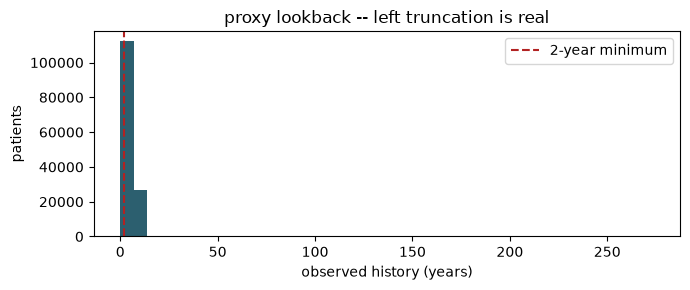


5558 patients (4.0%) have under 2 years of history.
Exclude them from any analysis that depends on the ABSENCE of a code.


In [4]:
win = eo.observation_window(events)
print(win.lookback_days.describe().round(0).to_string())

plt.figure(figsize=(7, 3))
plt.hist(win.lookback_days / 365.25, bins=40, color='#2C5F6F')
plt.axvline(2, ls='--', c='firebrick', label='2-year minimum')
plt.xlabel('observed history (years)'); plt.ylabel('patients')
plt.title('proxy lookback -- left truncation is real'); plt.legend()
plt.tight_layout(); plt.show()

SHORT = win.loc[win.lookback_days < 730, 'person_id']
print(f"\n{len(SHORT)} patients ({len(SHORT)/len(win):.1%}) have under 2 years of history.")
print("Exclude them from any analysis that depends on the ABSENCE of a code.")

## 2 · Concept sets, resolved by name

`CODESETS` in `ethos_omop.py` maps a clinical label to name patterns plus vocabularies.
Resolving by name rather than hardcoding concept_ids means the same notebook runs against
real Snowflake concepts and the demo extract alike.

**Always eyeball the resolution before trusting it.** This is the step where a bad regex
quietly poisons everything downstream.

*In plain terms: instead of writing down a fixed list of magic numbers ("code 443698 means panic attack"), we write down a search pattern ("anything whose name matches panic_attack in the SNOMED vocabulary") and let the computer look up the matching codes every time. That way the same notebook keeps working even if the underlying code numbers differ between data sources.*

In [5]:
# Eyeball it: what did the "panic_attack" pattern actually match? Read
# straight from codesets.yaml (via eo.CODESETS) instead of retyping the
# patterns here, so this can't silently drift from what build_codesets()
# actually resolves.
pa_spec = eo.CODESETS['panic_attack']
eo.resolve(concept, pa_spec['patterns'], vocabularies=pa_spec.get('vocabularies'))

,concept_id,concept_name,vocabulary_id,concept_code,domain_id
17905,4189538,Agoraphobia without history of panic disorder,SNOMED,61569007,Condition
13871,436074,Panic disorder,SNOMED,371631005,Condition
24827,4147466,Panic disorder with agoraphobia,SNOMED,35607004,Condition


In [6]:
# On real data, roll a drug ingredient DOWN to all its products via concept_ancestor.
bz = codesets['benzodiazepine']
print("benzodiazepine concepts, direct:      ", len(bz))
print("benzodiazepine concepts, + descendants:", len(eo.expand_descendants(bz)))

# And roll an unspecified diagnosis UP to its parents -- directly useful for the
# unspecified chest pain codes (R07.8, R07.89) this whole cohort is built from.
cp = codesets['chest_pain']
print("chest pain parents, 1 level up:  ", len(eo.roll_up(cp, levels=1)))

benzodiazepine concepts, direct:       63
benzodiazepine concepts, + descendants: 63
chest pain parents, 1 level up:   4


In [7]:
# `tag` collapses many concept_ids into one readable clinical label.
# Untagged events fall back to a slug of concept_name so sequences stay legible.
print(events.tag.value_counts().head(15).to_string())
print(f"\ntagged into a codeset: {events.in_codeset.mean():.1%}")

tag
venipuncture_for_blo__procedure__4102442    706804
essential_hypertensi__disorder__320128      681523
ekg                                         672968
therapeutic_procedur__cpt4__2314284         633292
anxiety                                     551502
psych_eval_therapy                          495183
comprehensive_metabo__procedure__3661905    493339
complete_blood_count__procedure__4319466    491353
manual_therapy_techn__cpt4__2314290         469265
chest_pain                                  448598
lipid_panel_this_pan__cpt4__2212095         378338
low_back_pain__clinical_finding__194133     374177
t2dm                                        328672
chiropractic_manipul__cpt4__2314331         305693
neck_pain__clinical_finding__24134          297623

tagged into a codeset: 9.2%


Roughly a quarter to a third of events land in a curated codeset. That ratio is normal and
it is a useful number to report: it quantifies how much of the record your hand-built
domain knowledge actually covers. Zack's unknown-unknowns objection is exactly the other
two thirds.

*In plain terms: we only defined clinical labels (chest_pain, anxiety, panic_attack, ekg, ...) for the codes relevant to this specific question. Everything else in a patient's record still exists in the data, we just haven't given it a friendly name -- it isn't lost, and it's part of what later, more automated methods (Day 4's embeddings) can pick up on that our hand-picked labels can't.*

## 3 · The bag of codes, and the exact failure

In [8]:
X = eo.bag_of_codes(events, min_count=20)
print(X.shape)
X.iloc[:5, :10]

(139416, 15174)


tag,005_ml_afliberceptay__quant_branded_drug__1735886,007_ml_aflibercept_1__quant_branded_drug__747804,025_mg_05_mg_dose_15__branded_drug__793152,025_mg_05_mg_dose_3___branded_drug__741834,02_ml_glucagon_5_mgm__quant_branded_drug__37499704,02_ml_methotrexate_5__quant_branded_drug__45776920,02_ml_sarscov2_covid__quant_branded_drug__37355138,036_ml_follitropin_b__quant_branded_drug__43011837,03_ml_bremelanotide___quant_branded_drug__1361652,03_ml_enoxaparin_sod__quant_clinical_drug__40160970
person_id,,,,,,,,,,
22,0,0,0,0,0,0,0,0,0,0
50,0,0,0,0,0,0,0,0,0,0
67,0,0,0,0,0,0,0,0,0,0
68,0,0,0,0,0,0,0,0,0,0
321,0,0,0,0,0,0,0,0,0,0


**Goal:** get a feel for `X` before we do anything clever with it — which codes are common, which are rare, and how that's different from what an NMF component (two sections down) will tell us.

Prevalence read directly off `X`, before any factorization -- contrasted with the NMF-loading readout two sections down. A loading tells you what's characteristic of a *component*, not how common a code is overall: `chest_pain` is ~100% prevalent here yet won't dominate any single NMF component once it's dropped as near-constant.

*In plain terms: "prevalence" here just means "what % of patients have this code at all." That's a different question from "which codes define this cluster/component" -- a code can be common across the whole cohort (like `chest_pain`, since that's how the cohort was defined) without being distinctive of any particular subgroup.*

15174 codes, prevalence range 0.001% - 100.000%


,prevalence
tag,
chest_pain,100.0%
ekg,83.9%
venipuncture_for_blo__procedure__4102442,72.3%
comprehensive_metabo__procedure__3661905,68.4%
complete_blood_count__procedure__4319466,67.9%
lipid_panel_this_pan__cpt4__2212095,64.0%
general_examination___procedure__4036803,58.3%
hba1c,52.1%
thyroid_stimulating___procedure__4246879,43.5%


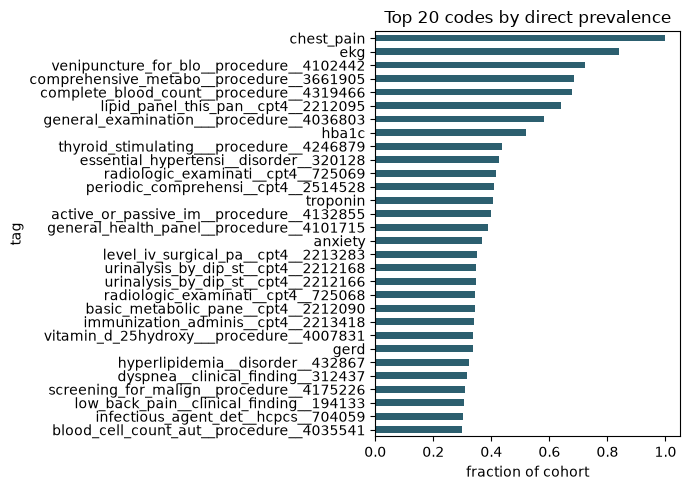

In [9]:
prevalence = X.mean().sort_values(ascending=False)
print(f"{len(prevalence)} codes, prevalence range "
      f"{prevalence.min():.3%} - {prevalence.max():.3%}")
display(prevalence.head(30).to_frame('prevalence').style.format('{:.1%}'))

plt.figure(figsize=(7, 5))
prevalence.head(30).iloc[::-1].plot.barh(color='#2C5F6F')
plt.xlabel('fraction of cohort'); plt.title('Top 20 codes by direct prevalence')
plt.tight_layout(); plt.show()

### Choosing `min_count` from prevalence

`bag_of_codes(min_count=...)` drops a code unless it has at least that many **events** in the
whole cohort, so one patient with 20 refills can keep a code alive. What actually limits a
model is how many **patients** carry a code, so this cell works in patients.

*In plain terms: a code seen in only a handful of patients can't form a reliable pattern, but
dropping too many codes throws away real signal. This table shows, for each cutoff, how many
columns survive and how much of the patient-by-code information is kept, then suggests a
cutoff.*

The suggested floor is the number of patients a code needs so that a training split is
expected to contain at least `MIN_TRAIN_PATIENTS` of them: `ceil(MIN_TRAIN_PATIENTS * cohort /
N_TRAIN)`. It scales with cohort size. It is a heuristic, not a statistical test, and it works
on `events`, so it does not need the full matrix (which would be too large to build with no
cutoff).

,prevalence_%,columns,pairs_kept_%
rule,,,
>= 1 patients,0.0007,27361,100.00
>= 2 patients,0.0014,22315,99.96
>= 5 patients,0.0036,17376,99.86
>= 10 patients,0.0072,14303,99.70
>= 20 patients,0.0143,11451,99.39
>= 35 patients,0.0251,9358,98.97
>= 50 patients,0.0359,8150,98.59
>= 100 patients,0.0717,6106,97.48
>= 200 patients,0.1435,4485,95.71


cohort 139416 patients, training split 20000
suggested floor: 35 patients (0.025% prevalence) -> 9358 of 27361 columns, 99.0% of patient-code pairs kept
codeset tags below the floor: none


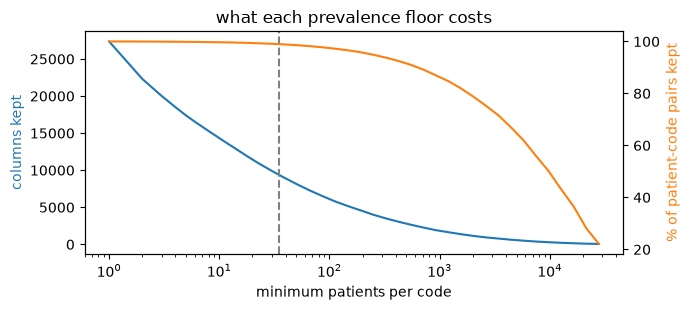


To apply it, build X from the kept codes only (min_count=1 on pre-filtered events):
    X = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)


In [10]:
import math

MIN_TRAIN_PATIENTS = 5            # a code should appear in >= this many patients of a training split
n_pat   = events.person_id.nunique()
N_TRAIN = min(20_000, int(0.6 * n_pat))      # training-split size used by the k-sweep cells

# patients per code, and events per code (what bag_of_codes' min_count counts)
code, tags = pd.factorize(events['tag'])
key        = events['person_id'].to_numpy(np.int64) * len(tags) + code
prev_pat   = pd.Series(np.bincount(np.unique(key) % len(tags), minlength=len(tags)), index=tags)
ev_cnt     = pd.Series(np.bincount(code, minlength=len(tags)), index=tags)
all_pairs  = int(prev_pat.sum())             # distinct (patient, code) pairs = ones in the full 0/1 matrix

def summarize(mask):
    return {'columns': int(mask.sum()),
            'pairs_kept_%': round(100 * prev_pat[mask].sum() / all_pairs, 2)}

rows = [{'rule': f'>= {p} patients', 'prevalence_%': round(100 * p / n_pat, 4), **summarize(prev_pat >= p)}
        for p in [1, 2, 5, 10, 20, 35, 50, 100, 200, 500]]
rows.append({'rule': 'current min_count=20 (events)', 'prevalence_%': np.nan, **summarize(ev_cnt >= 20)})
rule_tbl = pd.DataFrame(rows).set_index('rule')

MIN_PATIENTS = math.ceil(MIN_TRAIN_PATIENTS * n_pat / N_TRAIN)
KEEP_TAGS    = prev_pat.index[prev_pat >= MIN_PATIENTS]
display(rule_tbl)

# the clinical (codeset) tags are the ones the analysis is about -- do any fall below the floor?
codeset_tags = [t for t in codesets if t in prev_pat.index]
lost = prev_pat[codeset_tags][lambda s: s < MIN_PATIENTS]
print(f"cohort {n_pat} patients, training split {N_TRAIN}")
print(f"suggested floor: {MIN_PATIENTS} patients ({100 * MIN_PATIENTS / n_pat:.3f}% prevalence) -> "
      f"{len(KEEP_TAGS)} of {len(prev_pat)} columns, "
      f"{100 * prev_pat[KEEP_TAGS].sum() / all_pairs:.1f}% of patient-code pairs kept")
print("codeset tags below the floor:", lost.to_dict() if len(lost) else "none")

fig, ax = plt.subplots(figsize=(7, 3.2))
ps = np.unique(np.round(np.geomspace(1, max(2, prev_pat.max() / 5), 40)).astype(int))
ax.plot(ps, [(prev_pat >= p).sum() for p in ps], color='C0')
ax.set_xscale('log'); ax.set_xlabel('minimum patients per code'); ax.set_ylabel('columns kept', color='C0')
ax2 = ax.twinx()
ax2.plot(ps, [100 * prev_pat[prev_pat >= p].sum() / all_pairs for p in ps], color='C1')
ax2.set_ylabel('% of patient-code pairs kept', color='C1')
ax.axvline(MIN_PATIENTS, ls='--', c='grey')
ax.set_title('what each prevalence floor costs')
plt.tight_layout(); plt.show()

print("\nTo apply it, build X from the kept codes only (min_count=1 on pre-filtered events):")
print("    X = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)")

In [11]:
X = eo.bag_of_codes(events[events.tag.isin(KEEP_TAGS)], min_count=1)
print(X.shape)

(139416, 9358)


In [12]:
# Two dx_9487 patients with a near-IDENTICAL bag of codes and opposite triage answers.
weak = eo.chest_pain_labels(events)                 # rule-based probe labels: psych vs cardiac
lab  = weak.set_index('person_id').chest_pain_label

both = [p for p in X.index
        if X.loc[p].get('chest_pain', 0) == 1
        and X.loc[p].get('ekg', 0) == 1
        and p in lab.index]

a = next((p for p in both if lab[p] == 'psych'),   None)
b = next((p for p in both if lab[p] == 'cardiac'), None)
assert a and b, ("No matching-bag pair found in this sample. Widen the `both` filter, "
                 "or inspect `both` to see which side is missing.")

print("bag-of-codes view -- indistinguishable on chest_pain + ekg alone:")
display(X.loc[[a, b], ['chest_pain', 'ekg']])

print("\nactual timelines -- obviously different:")
FOCUS = ['chest_pain', 'ekg', 'anxiety', 'panic_attack', 'ssri', 'benzodiazepine',
         'troponin', 'stress_test', 'coronary_angio', 'cad']
for pid in (a, b):
    s = events[(events.person_id == pid) & events.tag.isin(FOCUS)]
    print(f"\n  person_id {pid}  ({lab[pid]})")
    print(s[['event_date', 'tag']].drop_duplicates('tag').to_string(index=False))

chest_pain patients: 139416   labelled: 64289   both-evidence (dropped): 34411   no-evidence (dropped): 40716
bag-of-codes view -- indistinguishable on chest_pain + ekg alone:


tag,chest_pain,ekg
person_id,,
50,1,1
389,1,1



actual timelines -- obviously different:

  person_id 50  (psych)
event_date        tag
2019-11-11        ekg
2021-11-30 chest_pain
2024-10-23    anxiety

  person_id 389  (cardiac)
event_date        tag
2023-06-29 chest_pain
2025-09-30        ekg
2025-09-30   troponin


**That is the motivation for the whole week.** Near-identical features, opposite triage
answer. The information lives in the order and the surrounding evidence, and a flat bag of
codes throws both away.

This is not a modelling failure. No estimator can recover something the input does not
contain.

*In plain terms: this isn't a case of "use a fancier algorithm and it'll figure it out." The bag-of-codes table literally does not contain the information needed to tell these two patients apart -- both rows are 1, 1. No amount of machine learning can pull a distinction out of data where the distinction was never recorded in the first place. You have to fix the representation, not the model.*

### On `chest_pain_labels()`

There is no adjudicated ground truth for "was this actually cardiac." `chest_pain_labels()`
builds probe labels from **corroborating co-evidence only** — anxiety/panic diagnoses,
SSRIs, or benzodiazepines on the `psych` side; troponin, stress tests, coronary
angiography, or a CAD diagnosis on the `cardiac` side. Patients with both kinds of
evidence, or neither, are dropped, and the counts are printed so you can see how many.

*In plain terms: instead of guessing the reason for the chest pain directly, we look for other, more specific evidence nearby — did the patient also have an anxiety/panic diagnosis or an SSRI/benzodiazepine prescription? Did they also have a troponin, stress test, or coronary angiography? If the evidence points clearly one way, we use that as the label. If it points both ways, or neither way, we honestly say "we don't know" and drop them rather than force a guess.*

**The time order is deliberately not used here.** If you labelled by "anxiety dx before
chest pain code" and then tested whether the order predicts the label, you'd get perfect
accuracy by construction and learn nothing. Days 3-4 test order directly — the label has to
stay independent of it, or the test is circular.

*In plain terms: it would be tempting to say "anxiety diagnosis came before the chest pain code, so it must be psych-related." But that's using the very thing we're trying to test (timing) to build the answer key -- then "discovering" that timing predicts the answer would be circular, not a real finding. So the answer key is built from a different, independent kind of evidence, and timing is only used afterward to see if it can predict that answer.*

In [13]:
from sklearn.metrics import pairwise_distances
import scipy.sparse as sp

# chest_pain is the cohort anchor -- ~100% prevalence here, so it's a near-
# constant column that carries no discriminative signal and would just eat a
# component. Drop it before any distance/SVD/NMF fit; X itself (with the
# column) stays untouched for the two-patient demo above and Table 1 below.
# Everything downstream works on a SPARSE copy (Xs): same values as the dense matrix without the
# anchor column, a fraction of the memory, and faster NMF / SVD. No dense copy without
# `chest_pain` is ever built.
nmf_cols = X.columns.drop('chest_pain')                  # code names for the components
n_pat    = X.shape[0]
Xs = sp.csr_matrix(X.to_numpy())[:, X.columns.get_indexer(nmf_cols)].astype(float).tocsr()
print(f"Xs {Xs.shape}, density {Xs.nnz / (Xs.shape[0] * Xs.shape[1]):.3%}")

def dist_to_all(row, M, metric, chunk=10_000):
    """Distances from one row to every row of sparse M, densifying only `chunk` rows at a time."""
    return np.concatenate([pairwise_distances(row, M[i:i + chunk].toarray(), metric=metric)[0]
                           for i in range(0, M.shape[0], chunk)])

sub = Xs[:400].toarray()
for m in [#'euclidean', 
          'cosine', 'jaccard']:
    D  = pairwise_distances(sub, metric=m)
    iu = np.triu_indices(len(sub), 1)
    print(f"{m:10s} mean={D[iu].mean():.3f}  sd={D[iu].std():.3f}")

pos = list(X.index).index(a)
print()
for m in [#'euclidean', 
          'cosine', 'jaccard']:
    D  = dist_to_all(Xs[pos:pos+1].toarray(), Xs, m)
    nn = [X.index[i] for i in np.argsort(D)[1:6]]
    print(f"{m:10s} neighbours of {a}: {[lab.get(p, '?') for p in nn]}")

Xs (139416, 9357), density 0.976%
cosine     mean=0.876  sd=0.065


/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


jaccard    mean=0.940  sd=0.036

cosine     neighbours of 50: ['cardiac', 'cardiac', '?', '?', '?']


/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)
/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric ja

jaccard    neighbours of 50: ['cardiac', 'cardiac', '?', '?', 'psych']


/opt/miniconda3/envs/ethos_llm/lib/python3.13/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


**Rule of thumb for claims: use cosine on binary or count code vectors.** Euclidean punishes
patients simply for having long histories, so the distance ends up driven by utilisation
volume rather than clinical content — which in your data is partly a function of what got
ordered during underwriting.

*In plain terms: a patient with 200 recorded codes isn't automatically "less similar" to everyone else than a patient with 20 codes — but a naive distance metric (Euclidean) treats it that way, because it's sensitive to how many codes are turned on, not just which ones. Cosine distance cares about the pattern of codes, not the raw count, which is what we actually want to compare.*

## 5 · The curse of dimensionality

On the full Ethos vocabulary you will have tens of thousands of columns, not the few dozen
here. At that width every pair of patients becomes equidistant and "nearest neighbour" stops
meaning anything.

*In plain terms: with only a handful of columns, "similar" and "different" are easy to tell apart. Once you have tens of thousands of columns and each patient only has a handful of them turned on, almost every pair of patients ends up looking roughly equally (dis)similar to each other -- there's no longer a meaningful "close" versus "far." This is a general math fact (the "curse of dimensionality"), not something specific to our data.*

In [14]:
rng = np.random.default_rng(0)
print(f"{'dims':>6} {'min/max distance ratio':>24}")
for d in [10, 50, 200, 1000, 5000]:
    Zr = (rng.random((200, d)) < 0.02).astype(float)     # sparse, like code data
    D  = pairwise_distances(Zr)
    iu = np.triu_indices(200, 1)
    print(f"{d:>6} {D[iu].min() / D[iu].max():>24.3f}")
print("\nRatio -> 1 means every patient is equally far from every other.")

  dims   min/max distance ratio
    10                    0.000
    50                    0.000
   200                    0.000
  1000                    0.568
  5000                    0.782

Ratio -> 1 means every patient is equally far from every other.


## 6 · Truncated SVD and NMF

**Goal:** compress thousands of sparse code columns down into a handful of numbers per patient that are actually usable for distance/clustering/visualization — and see two different ways of doing that compression.

*In plain terms: both methods below take the wide, sparse `X` table (thousands of mostly-zero columns) and produce a much narrower table (a few dozen columns) that still captures most of the real signal. Think of it as automatic summarization of a patient's code history into a small number of "themes." SVD and NMF differ in what kind of themes they're allowed to produce -- that difference is exactly why we look at both.*

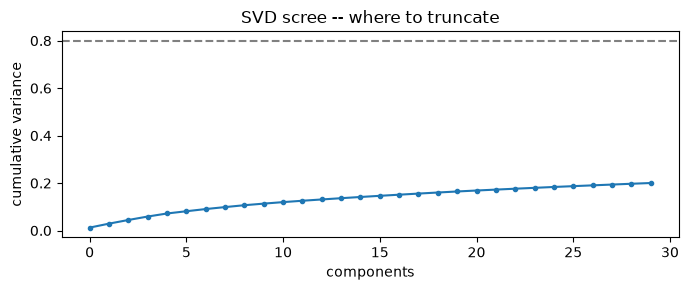

In [15]:
from sklearn.decomposition import TruncatedSVD, NMF
from sklearn.preprocessing import normalize

Xn  = normalize(Xs)                                  # cosine geometry, done properly
svd = TruncatedSVD(n_components=min(30, Xs.shape[1] - 1), random_state=0).fit(Xn)
Z   = svd.transform(Xn)

plt.figure(figsize=(7, 3))
plt.plot(np.cumsum(svd.explained_variance_ratio_), marker='o', ms=3)
plt.axhline(0.8, ls='--', c='grey')
plt.xlabel('components'); plt.ylabel('cumulative variance')
plt.title('SVD scree -- where to truncate'); plt.tight_layout(); plt.show()

### NMF and Choosing k for the NMF

The k=12 above was chosen by reading the components. This sweep adds numbers for it, the
NMF counterpart of Day 2's elbow + silhouette + bootstrap-ARI table for KMeans.

*In plain terms: fit the NMF at several values of k and, for each one, check how well it
explains patients it was never fit on, how well separated the resulting patient groups are
(silhouette), and whether the same bundles come back on re-draws. Then pick a k where adding
more components stops paying for itself but the bundles are still reproducible.*

Every k is fit on the same `N_SWEEP` training patients and scored on a disjoint `N_HELD`
held-out set, so the comparison is fair and the error is not just training fit. The
silhouette is computed in the SVD space (`Z`) that Day 2 used for KMeans, not in NMF's own
loading space, which would be circular because those loadings defined the groups.

The whole sweep is repeated on every split in `SPLIT_SEEDS` (independent random train / held-out
splits of the cohort), each with `N_BOOT_K` bootstrap refits per k. More refits only sharpen the
estimate within one split. Several splits show whether a k looks stable only because of the
patients it happened to see. Every NMF fit in this section uses the same settings (`NMF_KW`,
defined in the stability cell), so the base fit and its refits are converged the same way.

The fits run in parallel (`N_JOBS` workers, because sklearn's NMF uses one core per fit) on a
sparse copy of the matrix, `Xs`. The result is the same as the dense serial version; it is only
faster and much smaller in memory.

In [16]:

from scipy.optimize import linear_sum_assignment
from sklearn.metrics import adjusted_rand_score
import time

# one place for the NMF fit settings, used by every NMF fit in this section
NMF_KW = dict(init='nndsvd', random_state=0, max_iter=2000, tol=1e-4)

N_BOOT        = 10        # refits; each is a full NMF fit, raise once you know the runtime
N_BOOT_SAMPLE = 20_000    # patients per resample (capped at the cohort size)
N_EVAL        = 20_000    # fixed patients used to compare argmax labels across refits

def _unit(M):
    return M / np.linalg.norm(M, axis=1, keepdims=True)

def nmf_stability(nmf_base, Xv, n_boot=N_BOOT, n_sample=N_BOOT_SAMPLE,
                  n_eval=N_EVAL, seed=0):
    """Bootstrap-refit NMF; return per-component matched cosine and per-boot ARI.

    Component order is arbitrary between fits (label switching), so each refit's
    components are matched to the base fit's by cosine similarity (Hungarian
    algorithm). ARI compares argmax patient partitions, which needs no matching.
    """
    k    = nmf_base.n_components_
    Hb   = _unit(nmf_base.components_)
    rng  = np.random.default_rng(seed)
    ev   = rng.choice(Xv.shape[0], min(n_eval, Xv.shape[0]), replace=False)
    lab0 = nmf_base.transform(Xv[ev]).argmax(1)
    cos, ari = [], []
    for b in range(n_boot):
        t0  = time.perf_counter()
        idx = rng.choice(Xv.shape[0], min(n_sample, Xv.shape[0]), replace=True)
        m   = NMF(n_components=k, **NMF_KW).fit(Xv[idx])
        S        = Hb @ _unit(m.components_).T         # base x refit cosine
        rows, cols = linear_sum_assignment(-S)          # rows come back sorted 0..k-1
        cos.append(S[rows, cols])                       # cos[b][j] = base component j
        ari.append(adjusted_rand_score(lab0, m.transform(Xv[ev]).argmax(1)))
        print(f"  boot {b + 1}/{n_boot}  {time.perf_counter() - t0:.0f}s  "
              f"ARI {ari[-1]:.3f}")
    return np.array(cos), np.array(ari)

[Parallel(n_jobs=12)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=12)]: Done  50 out of  60 | elapsed:  3.2min remaining:   38.4s


60 jobs on 12 workers; summed fit time 41.0 CPU-min


[Parallel(n_jobs=12)]: Done  60 out of  60 | elapsed:  3.8min finished


,held_out_err,silhouette,ari_mean,ari_sd_splits,n_splits_solid,n_splits_sugg,cos_mean,n_unstable,n_used
k,,,,,,,,,
3,0.895,0.062,0.850,0.042,5,5,0.996,0.0,3
4,0.889,0.064,0.937,0.004,5,5,0.998,0.0,4
5,0.884,0.064,0.942,0.011,5,5,0.998,0.0,5
6,0.880,0.058,0.757,0.030,3,5,0.921,1.0,6
7,0.876,0.052,0.770,0.072,2,5,0.945,1.0,7
8,0.873,0.054,0.816,0.122,4,5,0.989,0.0,8
9,0.870,0.053,0.688,0.131,1,4,0.920,1.0,9
10,0.867,0.054,0.663,0.039,0,5,0.915,1.0,10
11,0.865,0.054,0.660,0.058,0,4,0.925,1.0,11


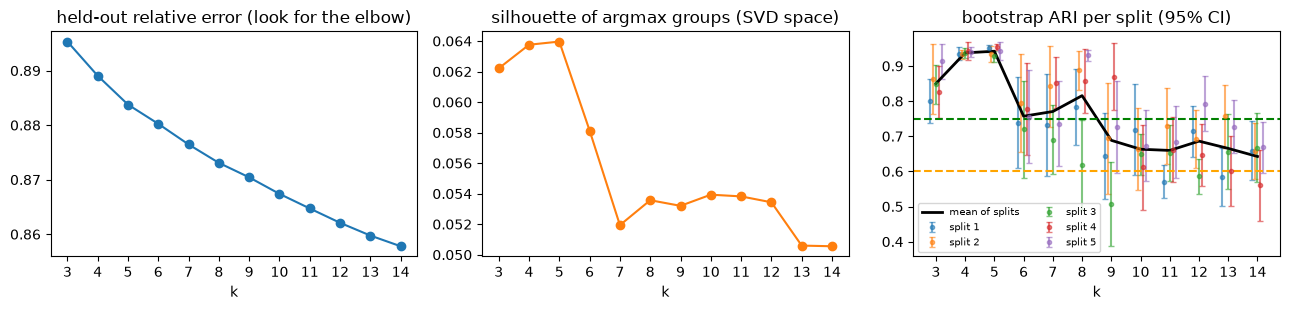

largest k with ARI >= 0.60 on 4+ of 5 splits and mean cos >= 0.75: 14
largest k with ARI >= 0.75 on 4+ of 5 splits and no unstable component (median): 8


In [17]:
import time
import io, contextlib
import os, math
import scipy.sparse as sp
from joblib import Parallel, delayed
from sklearn.metrics import silhouette_score
from scipy import stats

K_GRID      = list(range(3, 15))
SPLIT_SEEDS = (1, 2, 3, 4, 5)   # independent train / held-out splits of the cohort
N_SWEEP     = 20_000      # train patients every k is fit on
N_HELD      = 10_000      # disjoint held-out patients for error / silhouette
N_BOOT_K    = 10          # bootstrap refits per k and split (reuses nmf_stability above)
NC_SIL      = min(24, Z.shape[1])   # SVD dims Day 2 scored KMeans silhouette in
MIN_SPLITS_OK = math.ceil(0.8 * len(SPLIT_SEEDS))   # a k must pass on this many splits (4 of 5)
N_JOBS      = max(1, (os.cpu_count() or 2) - 2)   # sklearn's NMF is single-threaded: one fit per core

def rel_err(X, W, H):
    """||X - W H||_F / ||X||_F without building the dense W @ H (X may be sparse)."""
    x2    = X.multiply(X).sum() if sp.issparse(X) else (X ** 2).sum()
    cross = np.sum((X @ H.T) * W)
    quad  = np.sum((W.T @ W) * (H @ H.T))
    return float(np.sqrt(max(x2 - 2 * cross + quad, 0.0) / x2))

def sweep_job(split_seed, k, Xtr, Xho, Zho, n_boot):
    """All metrics for one (split, k): one base fit plus n_boot bootstrap refits."""
    t0 = time.perf_counter()
    m  = NMF(n_components=k, **NMF_KW).fit(Xtr)
    Wh = m.transform(Xho)
    lab_ho = Wh.argmax(1)
    with contextlib.redirect_stdout(io.StringIO()):          # silence per-boot prints
        cos, ari = nmf_stability(m, Xtr, n_boot=n_boot, n_sample=Xtr.shape[0],
                                 n_eval=Xtr.shape[0], seed=k)
    share = np.bincount(lab_ho, minlength=k) / len(lab_ho)
    return {'split': split_seed, 'k': k,
            'held_out_err': rel_err(Xho, Wh, m.components_),
            'silhouette': silhouette_score(Zho, lab_ho) if len(set(lab_ho)) > 1 else np.nan,
            'ari_mean': ari.mean(), 'ari_sd': ari.std(ddof=1),
            'ari_se': ari.std(ddof=1) / np.sqrt(n_boot),
            'cos_mean': cos.mean(), 'n_unstable': int((cos.mean(0) < .75).sum()),
            'n_used': int((share >= .01).sum()), 'secs': time.perf_counter() - t0}

def make_split(split_seed):                                   # sliced once here, so workers get small inputs
    perm   = np.random.default_rng(split_seed).permutation(Xs.shape[0])
    tr, ho = perm[:N_SWEEP], perm[N_SWEEP:N_SWEEP + N_HELD]
    return Xs[tr], Xs[ho], Z[ho, :NC_SIL]                     # Z rows align with Xs rows

splits  = {s: make_split(s) for s in SPLIT_SEEDS}
jobs    = [(s, k) for k in sorted(K_GRID, reverse=True) for s in SPLIT_SEEDS]   # slow (large k) first
results = Parallel(n_jobs=N_JOBS, verbose=5)(
              delayed(sweep_job)(s, k, *splits[s], N_BOOT_K) for s, k in jobs)
res       = pd.DataFrame(results)
per_split = {s: res[res.split == s].drop(columns=['split', 'secs']).set_index('k').sort_index()
             for s in SPLIT_SEEDS}
print(f"{len(jobs)} jobs on {N_JOBS} workers; summed fit time {res.secs.sum() / 60:.1f} CPU-min")

# one row per k, summarised over splits
g     = pd.concat(per_split, names=['split']).groupby('k')
sweep = pd.DataFrame({'held_out_err': g.held_out_err.mean(), 'silhouette': g.silhouette.mean(),
                      'ari_mean': g.ari_mean.mean(), 'ari_sd_splits': g.ari_mean.std(),
                      'n_splits_solid': g.ari_mean.apply(lambda a: int((a >= .75).sum())),
                      'n_splits_sugg':  g.ari_mean.apply(lambda a: int((a >= .60).sum())),
                      'cos_mean': g.cos_mean.mean(), 'n_unstable': g.n_unstable.median(),
                      'n_used': g.n_used.min()})
display(sweep.round(3))

t_crit = stats.t.ppf(0.975, N_BOOT_K - 1)    # few refits -> t interval, not 1.96
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
ax[0].plot(sweep.index, sweep.held_out_err, marker='o')
ax[0].set_title('held-out relative error (look for the elbow)')
ax[1].plot(sweep.index, sweep.silhouette, marker='o', color='C1')
ax[1].set_title('silhouette of argmax groups (SVD space)')
for i, s in enumerate(SPLIT_SEEDS):                          # small x-offset so splits do not overlap
    d = per_split[s]
    ax[2].errorbar(d.index + (i - (len(SPLIT_SEEDS) - 1) / 2) * 0.1, d.ari_mean,
                   yerr=t_crit * d.ari_se, fmt='o', ms=3, capsize=2, alpha=.6, label=f'split {s}')
ax[2].plot(sweep.index, sweep.ari_mean, 'k-', lw=2, label='mean of splits')
ax[2].axhline(0.75, ls='--', c='green');  ax[2].axhline(0.60, ls='--', c='orange')
ax[2].set_title('bootstrap ARI per split (95% CI)'); ax[2].legend(fontsize=7, ncol=2)
for a in ax: a.set_xlabel('k'); a.set_xticks(sweep.index)
plt.tight_layout(); plt.show()

ok     = sweep[(sweep.n_splits_sugg >= MIN_SPLITS_OK) & (sweep.cos_mean >= .75)]
strong = sweep[(sweep.n_splits_solid >= MIN_SPLITS_OK) & (sweep.n_unstable == 0)]
print(f"largest k with ARI >= 0.60 on {MIN_SPLITS_OK}+ of {len(SPLIT_SEEDS)} splits and mean cos >= 0.75:",
      int(ok.index.max()) if len(ok) else "none")
print(f"largest k with ARI >= 0.75 on {MIN_SPLITS_OK}+ of {len(SPLIT_SEEDS)} splits and no unstable component (median):",
      int(strong.index.max()) if len(strong) else "none")

### Reading the k sweep

- **Silhouette** is the KMeans-style number: how much closer each held-out patient is to
  their own `argmax` group than to the next nearest one, in the same SVD space Day 2 scored
  KMeans in. Closer to 1 is better. Expect it to be **low in absolute terms** (NMF groups are
  soft themes, not tight blobs) and to **fall as k grows**, so read the *shape*, not the
  level.
- **Held-out error** always falls as k grows, so the *elbow* is what matters, not the minimum.
- **ARI / cos** are the same bootstrap checks as above, now per k and per split. `ari_mean` is
  the average over splits and `ari_sd_splits` its spread; `n_splits_solid` / `n_splits_sugg` count
  the splits with ARI at or above 0.75 / 0.60. `n_unstable` is the median over splits. Stability
  usually decays as k rises; the largest k that still passes is an upper bound.
- **Same ranking on most splits:** the pattern belongs to k, not to the patients drawn. Prefer
  the largest k that is solid on at least 4 of 5 splits (`MIN_SPLITS_OK`). **Splits disagree
  (large `ari_sd_splits`), or neighbouring k overlap within their 95% intervals:** stability
  cannot separate them, so choose on clinical readability and keep the "suggestive" caveat on
  any k below 0.75.
- Compare k by the interval (`ari_se`), not by `ari_sd`. `ari_sd` is the spread across refits
  and does not shrink with more refits; `ari_se` does.
- **`n_used`** counts components that are the dominant component for at least 1% of held-out
  patients. A k where `n_used` stops growing is adding redundant or dead components.
- No single column picks k. A defensible k sits **after the error elbow and before stability
  collapses**, with a silhouette not much worse than its neighbours. The final check is still
  whether the extra components read as distinct clinical bundles, as in the k=12 discussion.

### Are those 11 components stable? Bootstrap validation of the NMF
Now let's focus on looking stability within K=11
*In plain terms: re-run the NMF on random re-draws of the patients and see whether the same
code bundles show up. A bundle that keeps reappearing is real structure; one that only
appears for some draws is an accident of which patients were sampled.*

NMF component numbering is arbitrary between fits (component 3 in one run may be component 7
in the next), so each refit's components are first **matched** to the base fit's by cosine
similarity. Two outputs:

1. **Per component:** matched cosine between the base bundle and its refit counterpart.
2. **Cohort level:** ARI between the `argmax` patient labels, comparable with Day 2.

### Reading the stability table for K=11

- **`cos_mean` near 1** means the component's code bundle reappears almost unchanged in every
  resample. **Low `cos_mean` or high `cos_sd`** means the bundle depends on which patients
  happened to be drawn, so don't build a rule on it.
- The cosine cut-offs (0.90 solid, 0.75 suggestive) are working heuristics, not standards.
- **Bootstrap ARI** compares the `argmax` patient labels from each refit with the base
  labels, so it is directly comparable with Day 2's KMeans bootstrap ARI (0.75 solid, 0.60
  suggestive). A component can be stable as a *bundle* while the `argmax` *labels* are
  noisy, because soft loadings tie between bundles. High cos with low ARI is that case.
- Each refit sees only `N_BOOT_SAMPLE` patients, fewer than the base fit's full cohort, so
  this is a slightly pessimistic stability estimate.
- This validates stability, not meaning. Whether component 2 really is "cardiac workup" is
  still the read-the-top-codes judgement above.

### Final Bundles for K=11

In [18]:
# NMF factorises into non-negative PARTS, so each component reads as a set of
# co-occurring codes. Unlike SVD components you can name them.
#
# In plain terms: NMF is only allowed to add codes together, never subtract
# them, so each component ends up looking like "a bundle of codes that tend
# to show up together" -- e.g. "anxiety + benzodiazepine" reads as an actual
# clinical bundle, not an abstract direction in space. That's why we print
# the top-10 codes per component below: it's how you check whether a
# component actually means something clinically, or is noise.

for k in [8]:
#for k in [11]:
    nmf = NMF(n_components=k, **NMF_KW).fit(Xs)
    H   = pd.DataFrame(nmf.components_, columns=nmf_cols)
    lab_k = nmf.transform(Xs).argmax(axis=1)
    dom = pd.Series(lab_k).value_counts().sort_index()
    # save the fit for reuse (Day 3 loads it instead of refitting); the tag keeps cohorts apart
    np.savez(f"nmf_k{k}_chestpain_v2.npz", H=H.to_numpy(), cols=np.array(H.columns, dtype=str),
             pids=X.index.to_numpy(), labels=lab_k)
    print (f"\nNMF with {k} components:")
    for c in range(k):
        n    = int(dom.get(c, 0))
        row  = H.iloc[c]
        top  = row.sort_values(ascending=False).head(10)
        share = (top / row.sum() * 100).round(1)
        # codes = [f"{name} ({pct}%)" for name, pct in share.items()]
        codes = [f"{name}" for name, pct in share.items()]
        print(f"component {c} (n={n}, {n / n_pat * 100:.1f}%): {codes}")


NMF with 8 components:
component 0 (n=30588, 21.9%): ['lipid_panel_this_pan__cpt4__2212095', 'venipuncture_for_blo__procedure__4102442', 'general_examination___procedure__4036803', 'ekg', 'comprehensive_metabo__procedure__3661905', 'hba1c', 'complete_blood_count__procedure__4319466', 'essential_hypertensi__disorder__320128', 'periodic_comprehensi__cpt4__2514528', 'active_or_passive_im__procedure__4132855']
component 1 (n=24409, 17.5%): ['21_methylprednisolon__clinical_pack__19129398', 'amoxicillin_875_mg_c__clinical_drug__19115197', '6_azithromycin_250_m__clinical_pack__19128020', 'prednisone_20_mg_ora__clinical_drug__1551170', 'ibuprofen_800_mg_ora__clinical_drug__19019074', 'amoxicillin_500_mg_o__clinical_drug__19073187', 'ssri', 'fluticasone_propiona__clinical_drug__36250141', 'acetaminophen_325_mg__clinical_drug__40162515', 'cephalexin_500_mg_or__clinical_drug__19075034']
component 2 (n=16800, 12.1%): ['gynecologic_examinat__procedure__4306780', 'infectious_agent_det__cpt4__221311

Read those out loud — several are recognisable clinical bundles. **That is already a crude
motif catalog**, from a three-line factorisation, no deep learning involved. Keep it in your
pocket for the conversation about effort versus value.

*In plain terms: no deep learning, no neural network -- just three lines of matrix math, and it already recovered groups that make clinical sense (a cardiac-workup bundle, a GERD-workup bundle, a procedural-sedation bundle). Worth remembering next time someone asks "why not jump straight to a fancy model?"*

### Reading the k=11 output

- 0 preventive, 1 acute infection pharmacy, 4 MSK/PT, 11 derm — background bundles, same
  reading as the breast-cancer cohort's k=12 fit on the same underlying claims population.
- 3 is procedural sedation (fentanyl/ondansetron/midazolam/propofol/dexamethasone) — a
  peri-procedural bundle, not itself diagnostic of psych vs cardiac.
- 5 is ambiguous, same as in the breast-cancer notebook: B12/vit D/free T4/ferritin/iron is
  a generic fatigue/anemia/thyroid panel, not obviously tied to either side of the
  hypothesis. Left unlabelled rather than forced into a bucket.
- 7 is acute respiratory infection (cough/URI/pharyngitis/COVID) — another benign-cause
  bundle, alongside GERD and costochondritis, that the cohort's working hypothesis says the
  data should be allowed to surface instead of psych.
- 8 is women's cancer screening (mammography/pap smear) and 10 is pregnancy/prenatal —
  both unrelated to chest pain, just base-rate utilization for this demographic.

**The cardiac side splits into two different kinds of evidence, not one bundle:**
- 2 is cardiac *workup* (troponin, EKG, CBC, metabolic panel) — the acute rule-out testing
  ordered *because of* the chest pain visit.
- 9 is cardiac *risk factors* (hypertension, hyperlipidemia, echocardiography, obesity,
  t2dm) — chronic comorbidity burden that predates and predisposes to a cardiac read,
  independent of any single visit.
- 6 is GERD/GI workup (endoscopy, biopsy, GERD, epigastric pain, colonoscopy) — the
  cohort's own stated alternative-explanation hypothesis, showing up as its own component.

**Notably absent: no component reads as psych/anxiety.** None of the 12 components put
anxiety, panic_attack, ssri, or benzodiazepine in their top-5 codes — the psych evidence
`chest_pain_labels()` uses to label patients doesn't dominate any single NMF bundle the way
cardiac workup, cardiac risk factors, and GERD workup each do. That's worth knowing before
Table 1: the NMF columns give a full, clinically-readable picture of *why* dx_9487 patients
were in the system, but "psych" isn't one of the picture's dominant themes at this k —
either it's spread thin across several components, or the corroborating evidence
(`chest_pain_labels()`'s `psych` side) is a weaker organizing signal in this data than
mastectomy/chemo evidence was for the breast-cancer cohort's fertility/oncology split.



### Where do the clinical codes sit? (loadings check)

Reading the top 5 codes per component can hide a code that matters but is never in anyone's top
5. This cell takes the clinical codes defined in `codesets.yaml` (the psych and cardiac evidence
tags that `chest_pain_labels()` uses, plus every other codeset) and shows, for each one, **how its
total loading is split across the components**. Each row sums to 100%.

*In plain terms: for every clinical code we defined by hand, which bundle "owns" it, and is it
spread thin across several bundles or concentrated in one? If the psych codes spread across many
components, that explains why no single bundle reads as psych.*

`owner` is the component with the largest share. `rank_in_owner` is the code's rank among all
codes inside that component (1 = the component's top code), so a high share with a rank in the
hundreds means the code is attached to that bundle but not what defines it. Only codes that have
a codeset tag appear here; conditions such as hypertension, hyperlipidemia or obesity are not in
`codesets.yaml`, so they are not covered by this check.

In [19]:
K_CHECK = nmf.n_components_      # the last fit above
m8 = nmf if nmf.n_components_ == K_CHECK else NMF(n_components=K_CHECK, **NMF_KW).fit(Xs)
H8 = pd.DataFrame(m8.components_, columns=nmf_cols)

# watch list comes from codesets.yaml (via eo), not hand-typed; the cohort anchor is excluded
WATCH = {
    'psych':          eo.PSYCH_TAGS,
    'cardiac':        eo.CARDIAC_TAGS,
    'other codesets': [t for t in eo.CODESETS
                       if t not in eo.PSYCH_TAGS + eo.CARDIAC_TAGS and t != 'chest_pain'],
}

rows, missing = [], []
for group, tags in WATCH.items():
    for tag in tags:
        if tag not in H8.columns or H8[tag].sum() == 0:
            missing.append(tag); continue
        share = H8[tag] / H8[tag].sum() * 100                       # this code's split across components
        own   = int(share.values.argmax())
        rows.append({'group': group, 'code': tag, **{f'c{i}': share.iloc[i] for i in range(K_CHECK)},
                     'owner': own, 'rank_in_owner': int((H8.iloc[own] > H8.at[own, tag]).sum() + 1)})

loadings = pd.DataFrame(rows).set_index(['group', 'code'])
comp_cols = [f'c{i}' for i in range(K_CHECK)]
display(loadings.style.format({c: '{:.0f}' for c in comp_cols}).background_gradient(
        axis=1, cmap='Blues', subset=comp_cols))
print("components (n, top code):",
      {i: (int((m8.transform(Xs).argmax(1) == i).sum()), H8.iloc[i].idxmax()[:28]) for i in range(K_CHECK)})
print("codeset tags with no column (dropped by the prevalence floor, or never occur):", missing or "none")

components (n, top code): {0: (30588, 'lipid_panel_this_pan__cpt4__'), 1: (24409, '21_methylprednisolon__clinic'), 2: (16800, 'gynecologic_examinat__proced'), 3: (17327, 'troponin'), 4: (8486, 'level_iv_surgical_pa__cpt4__'), 5: (19411, 'therapeutic_procedur__cpt4__'), 6: (11035, 'vitamin_b12_measurem__proced'), 7: (11360, 'cough__clinical_finding__254')}
codeset tags with no column (dropped by the prevalence floor, or never occur): ['ed_visit']


base fit: NMF k=8  (the `nmf` from the cell above)
  boot 1/10  1s  ARI 0.926
  boot 2/10  1s  ARI 0.916
  boot 3/10  2s  ARI 0.931
  boot 4/10  2s  ARI 0.921
  boot 5/10  1s  ARI 0.570
  boot 6/10  2s  ARI 0.930
  boot 7/10  2s  ARI 0.947
  boot 8/10  1s  ARI 0.936
  boot 9/10  2s  ARI 0.845
  boot 10/10  1s  ARI 0.933


,n,top_codes,cos_mean,cos_sd,cos_min,verdict
0,30588,"lipid_panel_this_pan__cpt4__2212095, venipunct...",0.999,0.000,0.999,solid
1,24409,"21_methylprednisolon__clinical_pack__19129398,...",0.999,0.000,0.999,solid
2,16800,"gynecologic_examinat__procedure__4306780, infe...",0.998,0.001,0.997,solid
3,17327,"troponin, therapeutic_prophyla__cpt4__2314215,...",0.998,0.000,0.997,solid
4,8486,"level_iv_surgical_pa__cpt4__2213283, screening...",0.994,0.003,0.986,solid
5,19411,"therapeutic_procedur__cpt4__2314284, manual_th...",0.998,0.000,0.998,solid
6,11035,"vitamin_b12_measurem__procedure__4032173, vita...",0.997,0.001,0.996,solid
7,11360,"cough__clinical_finding__254761, acute_upper_r...",0.998,0.000,0.997,solid



bootstrap ARI of argmax labels: mean 0.886  sd 0.108  (Day 2 cut-offs: >=0.75 solid, >=0.60 suggestive)


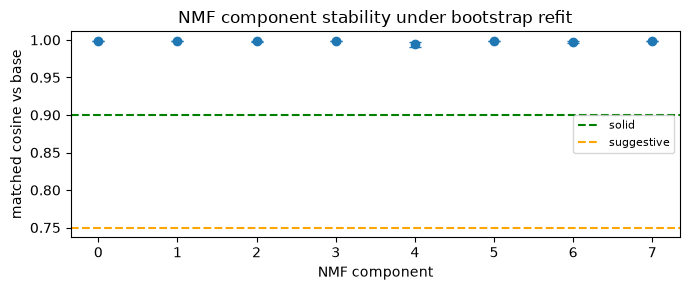

In [20]:


print(f"base fit: NMF k={nmf.n_components_}  (the `nmf` from the cell above)")
cos, ari = nmf_stability(nmf, Xs)

dom_n = pd.Series(nmf.transform(Xs).argmax(1)).value_counts().reindex(range(nmf.n_components_), fill_value=0)
top3  = [', '.join(pd.Series(nmf.components_[c], index=nmf_cols)
                   .nlargest(3).index) for c in range(nmf.n_components_)]
stab = pd.DataFrame({'n': dom_n.values, 'top_codes': top3,
                     'cos_mean': cos.mean(0).round(3), 'cos_sd': cos.std(0).round(3),
                     'cos_min': cos.min(0).round(3)})
stab['verdict'] = np.select([stab.cos_mean >= .90, stab.cos_mean >= .75],
                            ['solid', 'suggestive'], 'unstable')
display(stab)
print(f"\nbootstrap ARI of argmax labels: mean {ari.mean():.3f}  sd {ari.std():.3f}  "
      f"(Day 2 cut-offs: >=0.75 solid, >=0.60 suggestive)")

plt.figure(figsize=(7, 3))
plt.errorbar(stab.index, stab.cos_mean, yerr=stab.cos_sd, fmt='o', capsize=4)
plt.axhline(0.90, ls='--', c='green',  label='solid')
plt.axhline(0.75, ls='--', c='orange', label='suggestive')
plt.xlabel('NMF component'); plt.ylabel('matched cosine vs base')
plt.xticks(stab.index); plt.legend(fontsize=8)
plt.title('NMF component stability under bootstrap refit')
plt.tight_layout(); plt.show()

## 7 · t-SNE, and how not to over-read it

## Carry forward

`X`, `Z`, and the weak probe labels. Day 2 clusters `Z` and profiles back through `X`.

In [ ]:
# from sklearn.manifold import TSNE

# colour = (truth.set_index('person_id').archetype.reindex(X.index)
#           if truth is not None
#           else lab.reindex(X.index).fillna('unlabelled'))

# E = TSNE(n_components=2, init='pca', perplexity=30,
#          random_state=0).fit_transform(Z[:, :min(24, Z.shape[1])])

# fig, ax = plt.subplots(figsize=(7.5, 6))
# for name, g in pd.DataFrame({'x': E[:,0], 'y': E[:,1],
#                              'c': colour.values}).groupby('c', dropna=False):
#     ax.scatter(g.x, g.y, s=7, alpha=.6, label=str(name))
# ax.legend(fontsize=7, markerscale=2); ax.set_xticks([]); ax.set_yticks([])
# ax.set_title('t-SNE of bag-of-codes' +
#              (' -- coloured by planted truth (demo)' if truth is not None
#               else ' -- coloured by psych/cardiac label'))
# plt.tight_layout(); plt.show()

## Table 1 · Cohort description

Standard epidemiological Table 1 for the dx_9487 cohort: demographics and comorbidity
prevalence as rows, `Overall` plus each NMF component (patients whose *dominant* component
is that one) as columns. NMF-component columns give full coverage of the cohort -- unlike
the `psych`/`cardiac` split from `chest_pain_labels()`, which only labels part of the
cohort and drops the rest as ambiguous/no-evidence (see the assertion cell above). The
trailing p-value column tests, per row, whether that row's value actually differs across
the 12 NMF-component groups (Kruskal-Wallis for the continuous rows, chi-square for the
binary ones), or whether the apparent differences could just be noise.

*In plain terms: every patient in the cohort gets sorted into exactly one column, based on which NMF "theme" dominates their record. That gives a real, statistically usable breakdown of the whole cohort -- unlike splitting by the psych/cardiac probe label, which only had an opinion about part of the cohort. The trailing p-value column tells you, per row, whether that row's value actually differs across those NMF groups, or whether the apparent differences you see could just be noise.*

In [ ]:
from scipy import stats

cp_ids = set(events.loc[events.tag == 'chest_pain', 'person_id']) & set(X.index)

# age at first chest_pain, from person.birth_date
cp_index = eo.index_dates(events, 'chest_pain').set_index('person_id')['index_date']
birth    = person.set_index('person_id')['birth_date']
age_yrs  = (cp_index - birth.reindex(cp_index.index)).dt.days / 365.25

gender  = person.set_index('person_id')['gender'].astype(str).str.upper()
win_idx = win.set_index('person_id')['lookback_days']

# Evidence rows come straight from eo.PSYCH_TAGS / eo.CARDIAC_TAGS -- the same
# constants chest_pain_labels() used to build `lab` -- plus the remaining
# codesets.yaml tags as comorbidity/context rows, so this table shows exactly
# the evidence behind each patient's psych/cardiac label instead of a
# separately hand-typed list that can drift from it.
CODE_ROWS = (eo.PSYCH_TAGS + eo.CARDIAC_TAGS
             + ['gerd', 'costochondritis', 'ekg', 'beta_blocker', 'statin',
                't2dm', 'neuropathy', 'hba1c', 'ed_visit'])
missing = [t for t in CODE_ROWS if t not in eo.CODESETS]
assert not missing, f"Table 1 CODE_ROWS not in codesets.yaml: {missing}"
has = {t: set(events.loc[events.tag == t, 'person_id']) for t in CODE_ROWS}

# n_concepts: size of the RESOLVED codeset (post regex + vocabulary match),
# not the tag's prevalence in `events`. A codeset resolving to 0 concept_ids
# is a different failure mode than one that resolves fine but simply never
# occurs in this cohort -- both would otherwise show as a silent 0% below,
# so flag the unresolved ones loudly instead of leaving that ambiguous.
n_concepts = {t: len(codesets.get(t, set())) for t in CODE_ROWS}
unresolved = [t for t, n in n_concepts.items() if n == 0]
if unresolved:
    print("WARNING -- these codesets resolved to 0 concept_ids from their yaml "
          "patterns (0% below means UNRESOLVED, not necessarily absent):")
    print(" ", unresolved)

# dominant NMF component per patient, from the NMF already fit above (nmf, Xs, nmf_cols)
W = nmf.transform(Xs)
dom_component = pd.Series(W.argmax(axis=1), index=X.index)

# Labels come from eyeballing the top-5-codes-per-component printout above
# (cell 6dbc5233, k=12 fit) -- see the "Reading the k=12 output" discussion
# two cells up. The cardiac side splits into workup (2) / risk factors (9)
# rather than staying one bundle; GERD/GI workup (6) is the cohort's own
# stated alternative-explanation hypothesis showing up as its own component;
# the rest are background clinical bundles. Component 5 isn't named --
# nothing in its top codes maps cleanly to one of these groups. No component
# reads as psych/anxiety at this k (see the discussion). n_components comes
# from nmf.n_components_, not a literal count, so this can't silently drop
# components the way the old `for k in range(8)` version did with a
# 12-component fit.
COMPONENT_GROUPS = {0: 'preventive', 1: 'acute infection pharmacy',
                     2: 'cardiac workup', 3: 'procedural sedation',
                     4: 'MSK/PT',  5: 'generic fatigue',
                     6: 'GERD/GI workup',
                     7: 'acute respiratory infection',
                     8: "women's cancer screening",
                     9: 'cardiac risk factors', 10: 'pregnancy/prenatal',
                     11: 'derm'}
n_components = nmf.n_components_
col_name = lambda k: (f'NMF component {k} ({COMPONENT_GROUPS[k]})'
                       if k in COMPONENT_GROUPS else f'NMF component {k}')

# Columns: Overall, plus one column per NMF component -- patients whose
# dominant component is k -- instead of the psych/cardiac weak-label split
# above, which only covers part of the cohort. (The old 'non-cardiac' column
# here was also a no-op bug: `lab[lab != 'non-cardiac']` matches every row,
# since `lab`'s values are 'psych'/'cardiac', never the literal string
# 'non-cardiac'.) Every patient lands in exactly one component column here,
# giving full coverage of the cohort.
component_ids = {k: set(dom_component[dom_component == k].index) & cp_ids
                  for k in range(n_components)}
groups = {'Overall': cp_ids}
for k in range(n_components):
    groups[col_name(k)] = component_ids[k]
for name, ids in groups.items():
    print(f"{name}: {len(ids)} patients")

# p-value: is this row's distribution different across the 12 NMF-component
# groups? (Overall is their union, so it's excluded -- testing it against
# itself would be circular.) Nonparametric throughout: Kruskal-Wallis for the
# continuous rows (age, lookback -- no normality assumption), chi-square
# test of independence for the binary rows (Female, code prevalence).
def kruskal_p(series):
    samples = [series.reindex(ids).dropna().values for ids in component_ids.values()]
    samples = [s for s in samples if len(s) > 0]
    if len(samples) < 2:
        return float('nan')
    try:
        return stats.kruskal(*samples)[1]
    except ValueError:
        return float('nan')

def chisq_p(pos_ids):
    table = [[len(pos_ids & ids), len(ids - pos_ids)] for ids in component_ids.values()]
    try:
        return stats.chi2_contingency(table)[1]
    except ValueError:
        return float('nan')

def fmt_p(p):
    if pd.isna(p):
        return '--'
    return '<0.001' if p < 0.001 else f'{p:.3f}'

female_ids = set(gender[gender == 'FEMALE'].index)
p_values = {
    'Age, mean (SD)': kruskal_p(age_yrs),
    'Female, %': chisq_p(female_ids),
    'Lookback days, median (IQR)': kruskal_p(win_idx),
}
row_label = lambda t: f'{t} [n_concepts={n_concepts[t]}], %'
for t in CODE_ROWS:
    p_values[row_label(t)] = chisq_p(has[t])

def describe(ids):
    n = len(ids)
    if n == 0:
        return {'N (%)': '0 (0.0)'}
    row = {'N (%)': f"{n} ({n / len(cp_ids) * 100:.1f})"}
    a_yrs = age_yrs.reindex(ids)
    row['Age, mean (SD)'] = f"{a_yrs.mean():.1f} ({a_yrs.std():.1f})"
    row['Female, %'] = f"{(gender.reindex(ids) == 'FEMALE').mean() * 100:.1f}"
    lb = win_idx.reindex(ids)
    row['Lookback days, median (IQR)'] = (
        f"{lb.median():.0f} ({lb.quantile(.25):.0f}-{lb.quantile(.75):.0f})")
    for t in CODE_ROWS:
        row[row_label(t)] = f"{len(has[t] & ids) / n * 100:.1f}"
    return row

# Demographics + code prevalence as rows, Overall/NMF-component as columns,
# p-value (across the 12 component groups) as its own trailing column.
table1 = pd.DataFrame({name: describe(ids) for name, ids in groups.items()})
table1['p-value'] = pd.Series(p_values).reindex(table1.index).map(fmt_p)
display(table1)